# Diniz Ch.4 — Adaptive noise cancellation

primary d=clean+H(noise)，reference 是延遲 10 samples 的 clean+noise。評估使用 recovered=e=d−y 與 clean 的差，不把 residual signal power 當成 reconstruction MSE。此 reference 含 desired leakage。

來源：`Diniz-Chap4-Sys-Enhance.ipynb`。所有資料與結果留在記憶體，圖表使用共用深色風格。

執行順序：設定 → 參數與資料 → 模型與訓練 → 圖表與數值摘要。

## 1. Setup

In [ ]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Shared primary/reference generator

In [ ]:
from scipy.signal import lfilter

n_samples, n_trials, seed = 700, 20, 412
make_data = partial(data.enhancement, n_samples, reference_delay=10, noise_var=10.0)
impulse = np.r_[1.0, np.zeros(49)]
h = lfilter([0.4], [1.0, -1.36, 0.79], impulse)

## 3. Factories and common reconstruction metric

In [ ]:
models = {
  "LMS": partial(af.LMS, filter_order=20, mu=0.001),
  "NLMS": partial(af.NLMS, filter_order=20, mu=0.02, tau=1e-3),
  "APA P=1": partial(af.AffineProjection, filter_order=20, mu=0.5, P=1),
  "APA P=2": partial(af.AffineProjection, filter_order=20, mu=0.5, P=2),
  "Sign-Error LMS": partial(af.SignErrorLMS, filter_order=20, mu=0.02),
  "Sign-Sign LMS": partial(af.SignSignLMS, filter_order=20, mu=0.02),
  "DCT-LMS": partial(af.TransformDomain, filter_order=20, mu=0.02, matrix="dct"),
  "DFT-LMS": partial(af.TransformDomain, filter_order=20, mu=0.02, matrix="dft"),
}
results = training.compare(models, make_data, n_trials=n_trials, seed=seed, metric="reconstruction")

## 4. Reconstruction learning curve, residual and path response

In [ ]:
plot.learning(results, window=31, title="Noise canceller: |(d−y)−clean|²")
plot.show()
batch = make_data(rng=np.random.default_rng(np.random.SeedSequence(seed).spawn(1)[0]))
result = next(iter(results.values())).representative
plot.lines({
  "Clean": batch.clean[-250:],
  "Primary": batch.d[-250:],
  "Recovered d−y": result.e[-250:].real
}, title="One-trial tail reconstruction")
plot.show()
plot.frequency_response(
  {
    "Physical interference path": h,
    **{
      name: np.conj(res.representative.w_final)
      for name, res in results.items()
    }
  }, title="Interference path and learned adaptive filters")
plot.show()
training.summary(results)

## 原始題目附圖

以下保留上傳 notebook 的說明圖。

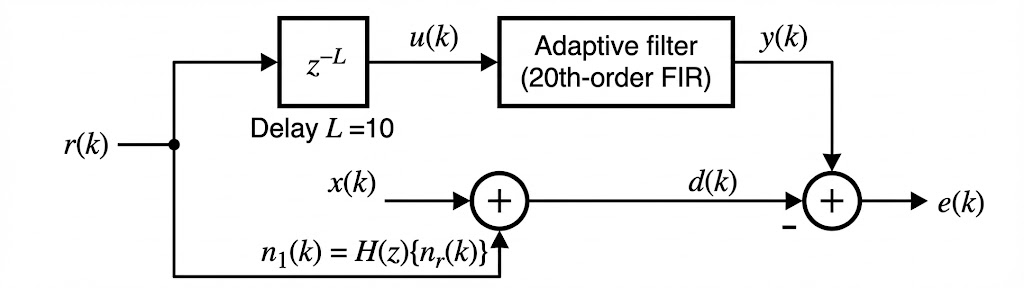